# PINNfluence in plain PyTorch

In this notebook we demonstrate how to interpret physics-informed neural networks (PINNs) using PINNfluence exemplified on the 1D drift-diffusion equation.

PINNfluence makes use of _Training Data Attribution_, i.e. it calculates the _influence_ of individual training points $x$, w.r.t. a given residual term $L$ (a.k.a. PINN loss-term) on arbitrary test points $z$, by approximating how $f(z)$ would change if $x$ were removed from training:
$$
\mathrm{Inf}(x,z)^{L \rightarrow f}_{\theta_0} = \nabla_\theta f(z; \theta_0) H^{-1}_{\theta_0} \nabla_\theta L(x; \theta_0)\quad,
$$
where $\theta_0$ are the trained model weights, $H^{-1}_{\theta_0}$ is the inverse Hessian w.r.t. the composite loss.
Note that $f$ can be any arbitrary function that depends on the model, such as the prediction directly, loss terms or any other desirable.

In order to use PINNfluence on your own PINN you only need to write a small wrapper (a `torch.nn.Module`) around your network such that it outputs individual residuals for each input.
See section 2 for a hands-on example. 
Then simply use the PINNfluence machinery from `pinnfluence_torch.py` to interpret your own PINN! 😊

**Prerequisites:** the main package installed as described in the root README (`uv pip install .` from the repository root), which brings PyTorch and the forked `captum`.

**Usage:** in the first code cell, you can switch between configs: 
- `CONFIG = "good"` (well-trained PINN) or `"bad"` (poorly-trained PINN, 5x fewer training points, suffering from information propagation failure). 
- With `TRAIN = False` the shipped checkpoint and its training points are loaded from `results/<CONFIG>/`. With `TRAIN = True` the model is retrained and that checkpoint is overwritten.

**Vocabulary.** Each influence score belongs to a `(test_term, train_term)` pair, matching $(f, L)$ in the formula above:
- *test term* ($f$): what is being explained at a test point $z$. In this notebook, always `output_0`, the prediction $u(x, t)$.
- *train term* ($L$): the training-side loss term through which a training point $x$ acts: `total_loss`, or one of the four loss terms `pde` (PDE residual), `ic` (initial condition), `bc_left` (periodic BC at $x = 0$) and `bc_right` (periodic BC at $x = 2\pi$). The paper and the main package call these `pde_0`, `bc_0`, `bc_1` and `bc_2`.

**Sign convention:** a positive score means that upweighting the training point pushes the test term up, a negative score means it pushes it down.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from tqdm import tqdm

from pinnfluence_torch import (
    PINNLossWrapper,
    compute_influence_matrix,
    compute_loss_fractions,
    instantiate_precomputed_influence,
)
from utils import Net, plot_loss_fractions_lineplot, plot_point_influence

torch.set_default_device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
np.random.seed(42)

CONFIG = "good"  # "good" or "bad" (under-resolved)
TRAIN = False  # False: load results/<CONFIG>/; True: retrain and overwrite it

# number of training points per configuration, as in the paper
CONFIGS = {
    "good": dict(num_domain=1000, num_boundary=100, num_initial=100),
    "bad": dict(num_domain=200, num_boundary=20, num_initial=20),
}
results_dir = Path("results") / CONFIG

## 1. The PINN

A PINN is a network $u_\theta(x, t)$ trained to minimize the PDE residual at collocation points inside the domain and the initial and boundary condition errors that hold at points sampled on $t = 0$ and on the spatial boundary respectively. These sampled points are the training data. The loss is the sum, over the loss terms, of the mean squared residual of each term at its points.

The problem here is the 1D drift-diffusion equation
$$
u_t = \alpha\, u_{xx} - \beta\, u_x, \qquad x \in [0, 2\pi],\ t \in [0, 1],
$$
with initial condition $u(x, 0) = \sin(2x + \pi/4)$, periodic boundary $u(0, t) = u(2\pi, t)$, $\alpha = 1$ and $\beta = 20$ (strongly advection-dominated). The loss has four terms: PDE residual, initial condition, and one term per side of the periodic boundary, so that influence can be attributed to each side separately.

In [2]:
# u_t = diffusivity * u_xx - advection * u_x
diffusivity = 1.0  # alpha
advection = 20.0  # beta
u_00 = 1.0
phase_shift = np.pi / 4
spatial_frequency = 2

t_start, t_end = 0.0, 1.0
x_start, x_end = 0.0, 2 * np.pi


def initial_condition(x: torch.Tensor) -> torch.Tensor:
    # u(x, t_start) for [B, 2] (x, t) rows, as [B, 1]
    return u_00 * torch.sin(spatial_frequency * x[:, 0:1] + phase_shift)


def solution(x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    # closed-form solution, used only for the error plots and the training log
    return (
        u_00
        * torch.sin(phase_shift + spatial_frequency * (x - advection * t))
        * torch.exp(-diffusivity * spatial_frequency**2 * t)
    )

## 2. Per-sample residuals: the module you write

This is the one piece you need to adapt to your own PINN.
Everything else should be hopefully generic enough to make it plug and play. 

To use PINNfluence, one needs to write one residual module (an `nn.Module`),
i.e. a wrapper over all losses and the PINN itself.
It needs a forward method that receives the PINN input coordinates and
returns point-wise residuals as individual columns, more concretely:
* `forward(x: [B, d_in]) -> [B, n_terms]`, one column per loss term, where each
  row depends only on its own input row.
* Note that initial and boundary conditions (and other subset-specific terms)
  should be masked to zero elsewhere.
  In our implementation we apply the PDE residual to all points, but this
  may also optionally be masked to zero on non-relevant points.
* To keep every parameter involved in the computation, add
  `zero = u.sum() * 0` to every column.
* A `.net` attribute holding the network.
  This allows for access to the network and influence attribution
  directly on the outputs.
* PINNfluence can be sped up by using input derivatives via
  `torch.func.grad` to make use of batched input derivatives efficiently.
  Alternatively one can use `torch.autograd.grad` with
  `vectorize="batched_grad"` set in `ArnoldiInfluenceFunctionPrecomputed`.

Squaring the columns (`PINNLossWrapper`) gives the per-sample, per-term losses.

In [3]:
TERMS = {"pde": 0, "ic": 1, "bc_left": 2, "bc_right": 3}  # loss term -> residual column


class DriftDiffusionResiduals(nn.Module):
    """forward(x: [B, 2]) -> [B, 4] per-sample residuals, columns as in TERMS:
        pde      : u_t - diffusivity * u_xx + advection * u_x
        ic       : (u - initial_condition(x)) * 1[t == t_start]
        bc_left  : (u(x_start, t) - u(x_end,   t)) * 1[x == x_start]
        bc_right : (u(x_end,   t) - u(x_start, t)) * 1[x == x_end]
    """

    def __init__(self, net: nn.Module) -> None:
        super().__init__()
        self.net = net

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        u = self.net(x)
        # keeps every net parameter in the autograd graph of every column
        zero_term = u.sum() * 0

        # rows are independent, so d(sum u)/dx is the per-row du/dx
        # alternatively one could use torch.autograd.grad with vectorize="batched_grad"
        # in the influence calculation. But it is slower.
        grad_u = torch.func.grad(lambda z: self.net(z).sum())
        u_x_t = grad_u(x)
        u_x = u_x_t[:, 0:1]
        u_t = u_x_t[:, 1:2]
        u_xx = torch.func.grad(lambda z: grad_u(z)[:, 0].sum())(x)[:, 0:1]
        # pde residual
        pde = u_t - diffusivity * u_xx + advection * u_x

        # initial condition residual
        ic_mask = (x[:, 1:2] == t_start).to(u.dtype)
        ic = (u - initial_condition(x)) * ic_mask

        # boundary condition residuals
        # Like DeepXDE's PeriodicBC (pair each boundary row with its mirror point
        # on the other side, same t), but once per side: bc_left, then bc_right.
        bcs = []
        for side_value, mirror_value in ((x_start, x_end), (x_end, x_start)):
            side_mask = (x[:, 0:1] == side_value).to(u.dtype)
            x_mirror = torch.cat(
                [torch.full_like(x[:, 0:1], mirror_value), x[:, 1:2]], dim=1
            )
            bcs.append((u - self.net(x_mirror)) * side_mask)

        return torch.cat([c + zero_term for c in (pde, ic, *bcs)], dim=1)

## 3. Training points

The training points are sampled to match the paper setup (i.e. matching DeepXDE's sampling -- The method does not depend on it though):
- `num_domain` collocation points.
- `num_initial` points at $t = 0$ with $x$ from the same sequence as above.
- `num_boundary // 2` points on each side, $x = 0$ and $x = 2\pi$, with $t$ uniform at random.

This is exactly the set DeepXDE samples, which the paper used. All points are stacked into one `[N, 2]` array of $(x, t)$ rows; these rows are what influence is attributed to. The test points, where predictions are explained, are a uniform $100 \times 100$ grid over the domain.

In [4]:
def van_der_corput(i: np.ndarray) -> np.ndarray:
    """Base-2 radical inverse: binary digits of i mirrored, e.g. 6 = 110b -> 0.011b."""
    bits = (i[:, None] >> np.arange(32)) & 1
    return bits @ 0.5 ** np.arange(1, 33)


def hammersley(n: int) -> np.ndarray:
    """[n, 2] points (van_der_corput(i), i / (n + 1)), i = 1..n, in (0, 1)^2."""
    i = np.arange(1, n + 1)
    return np.column_stack([van_der_corput(i), i / (n + 1)])


def sample_points(
    num_domain: int, num_boundary: int, num_initial: int, rng: np.random.Generator
) -> np.ndarray:
    """[N, 2] (x, t) rows: domain, initial (t = t_start), boundary x_start, boundary x_end."""
    lo, hi = np.array([x_start, t_start]), np.array([x_end, t_end])
    domain = lo + (hi - lo) * hammersley(num_domain)
    x_initial = x_start + (x_end - x_start) * van_der_corput(np.arange(1, num_initial + 1))
    initial = np.column_stack([x_initial, np.full(num_initial, t_start)])
    half = num_boundary // 2
    boundary = [
        np.column_stack([np.full(half, side), rng.uniform(t_start, t_end, half)])
        for side in (x_start, x_end)
    ]
    return np.vstack([domain, initial, *boundary])


def test_grid() -> np.ndarray:
    """Uniform 100 x 100 grid over the domain, as [10000, 2] (x, t) rows."""
    xx, tt = np.meshgrid(np.linspace(x_start, x_end, 100), np.linspace(t_start, t_end, 100))
    return np.column_stack([xx.ravel(), tt.ravel()])

## 4. Train, or load the checkpoint

The network is a tanh MLP with three hidden layers of 64 units whose inputs are scaled to $[0, 1]^2$. Training runs in float64: Adam (15 000 iterations, learning rate $10^{-3}$), then L-BFGS (5 x 1000 iterations, strong-Wolfe line search, settings mirroring DeepXDE's defaults). The training loss is the sum of the per-term MSEs, each averaged over its own points (PDE over all points, IC over the rows at $t = 0$, each BC over the rows on its side), i.e. the usual PINN loss. With `TRAIN = False` the shipped checkpoint and its training points are loaded instead.

> Training should only take minutes, so feel free to try yourself by switching the `TRAIN` argument in the first cell of this notebook.

In [5]:
net = Net(layer_sizes=[2, 64, 64, 64, 1], x_end=x_end, t_end=t_end)
residual_fn = DriftDiffusionResiduals(net)
loss_fn = PINNLossWrapper(mode="mse")  # squares the [B, 4] residuals


def loss_terms(x: torch.Tensor) -> dict[str, torch.Tensor]:
    """MSE of each loss term over its own rows (all rows for the PDE)."""
    losses = loss_fn(residual_fn(x))  # [B, 4]
    masks = [
        torch.ones_like(x[:, 0], dtype=torch.bool),
        x[:, 1] == t_start,
        x[:, 0] == x_start,
        x[:, 0] == x_end,
    ]
    return {name: losses[mask, col].mean() for (name, col), mask in zip(TERMS.items(), masks)}


@torch.no_grad()
def l2_error(x: torch.Tensor) -> torch.Tensor:
    """RMS error of the prediction against the closed-form solution (logging only)."""
    return torch.sqrt(torch.mean((net(x)[:, 0] - solution(x[:, 0], x[:, 1])) ** 2))


def train_adam(x_train: torch.Tensor, x_test: torch.Tensor, iterations: int, lr: float) -> None:
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    pbar = tqdm(range(iterations), desc="Adam")
    for it in pbar:
        opt.zero_grad()
        terms = loss_terms(x_train)
        total = sum(terms.values())
        total.backward()
        opt.step()
        if it % 100 == 0:
            pbar.set_postfix(
                {k: v.item() for k, v in terms.items()} | {"total": total.item()},
                l2_test=l2_error(x_test).item(),
            )


def train_lbfgs(x_train: torch.Tensor, x_test: torch.Tensor, iterations: int) -> None:
    # mirror DeepXDE's defaults
    opt = torch.optim.LBFGS(
        net.parameters(),
        lr=1,
        max_iter=1000,
        max_eval=1250,
        tolerance_change=0,
        tolerance_grad=1e-8,
        history_size=100,
        line_search_fn="strong_wolfe",
    )
    last = {}

    def closure():
        opt.zero_grad()
        terms = loss_terms(x_train)
        total = sum(terms.values())
        total.backward()
        last.update({k: v.item() for k, v in terms.items()}, total=total.item())
        return total

    # one L-BFGS step runs up to max_iter=1000 iterations, so log once per step
    pbar = tqdm(range(iterations // 1000), desc="L-BFGS")
    for _ in pbar:
        opt.step(closure)
        pbar.set_postfix(last, l2_test=l2_error(x_test).item())

In [6]:
x_test_np = test_grid()
if TRAIN:
    rng = np.random.default_rng(42)
    x_train_np = sample_points(**CONFIGS[CONFIG], rng=rng)
    x_train = torch.tensor(x_train_np)
    x_test = torch.tensor(x_test_np)
    train_adam(x_train, x_test, iterations=15_000, lr=1e-3)
    train_lbfgs(x_train, x_test, iterations=5_000)
    results_dir.mkdir(parents=True, exist_ok=True)
    torch.save(net.state_dict(), results_dir / "model.pth")
    np.savez(results_dir / "train_data.npz", x_train=x_train_np)
else:
    net.load_state_dict(
        torch.load(results_dir / "model.pth", map_location=torch.get_default_device())
    )
    x_train_np = np.load(results_dir / "train_data.npz")["x_train"]
net.eval()

print(f"train points (domain + IC + BC): {x_train_np.shape}")
print(f"test points:                     {x_test_np.shape}")

train points (domain + IC + BC): (1200, 2)
test points:                     (10000, 2)


## 5. Prediction vs. closed-form solution

Prediction, closed-form solution and their difference over the $(x, t)$ domain: a sanity check of the model before we explain it. With `TRAIN = True` the figure is also saved to `results/<CONFIG>/prediction.png`.

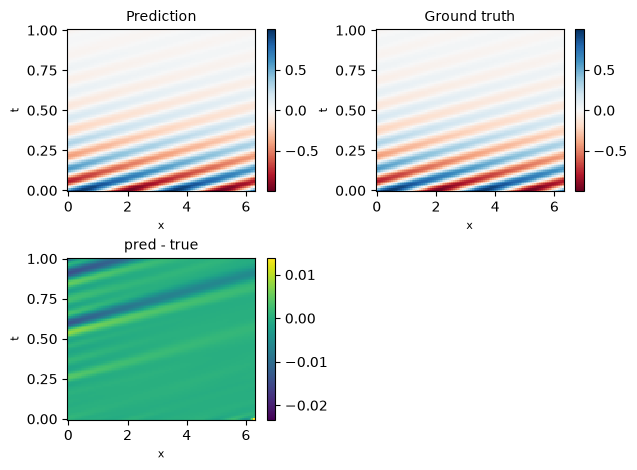

In [7]:
def plot_prediction(net: nn.Module) -> plt.Figure:
    """Prediction, closed-form solution and their difference on the test grid."""
    xt = torch.tensor(test_grid())
    with torch.no_grad():
        u_pred = net(xt)[:, 0]
    u_true = solution(xt[:, 0], xt[:, 1])
    xx, tt, u_pred, u_true = (
        v.reshape(100, 100).cpu().numpy() for v in (xt[:, 0], xt[:, 1], u_pred, u_true)
    )

    fig = plt.figure()
    panels = [
        ("Prediction", u_pred, "RdBu"),
        ("Ground truth", u_true, "RdBu"),
        ("pred - true", u_pred - u_true, None),
    ]
    for k, (title, u, cmap) in enumerate(panels):
        ax = fig.add_subplot(2, 2, k + 1)
        fig.colorbar(ax.pcolormesh(xx, tt, u, cmap=cmap), ax=ax)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("x", fontsize=8)
        ax.set_ylabel("t", fontsize=8)
    fig.tight_layout(h_pad=0.5, w_pad=0.5)
    return fig


fig = plot_prediction(net)
if TRAIN:
    fig.savefig(results_dir / "prediction.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. What do the residuals look like?

`residual_fn` maps a batch of points to a `[B, 4]` tensor of per-point residuals with columns `[pde, ic, bc_left, bc_right]` (the `ic` and BC columns are zero away from $t = 0$ and $x \in \{0, 2\pi\}$). Squaring them gives the per-term losses. Keeping the terms in separate columns is what makes per-term influence possible.

In [8]:
x_train = torch.tensor(x_train_np, requires_grad=True)

residuals = residual_fn(x_train[np.random.choice(x_train.shape[0], 10, replace=False), :])
print("Residuals:")
print(residuals)
print()

print("Losses (residuals squared):")
# note: loss is computed against zero targets because
# captum expects it like this.
print(loss_fn(residuals, torch.zeros_like(residuals)))

Residuals:
tensor([[ 0.0002,  0.0000,  0.0000, -0.0017],
        [-0.0015,  0.0000,  0.0000,  0.0000],
        [ 0.0028,  0.0000,  0.0000,  0.0000],
        [ 0.0020,  0.0000,  0.0000,  0.0000],
        [ 0.0035,  0.0000,  0.0000,  0.0000],
        [ 0.0043,  0.0000,  0.0023,  0.0000],
        [-0.0074,  0.0000,  0.0000,  0.0000],
        [-0.0024,  0.0000,  0.0000,  0.0000],
        [-0.0016,  0.0000,  0.0000,  0.0000],
        [-0.0012,  0.0000,  0.0000,  0.0000]], device='cuda:0',
       grad_fn=<CatBackward0>)

Losses (residuals squared):
tensor([[4.6582e-08, 0.0000e+00, 0.0000e+00, 2.8211e-06],
        [2.3397e-06, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [7.8684e-06, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [4.1328e-06, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [1.2459e-05, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [1.8738e-05, 0.0000e+00, 5.3753e-06, 0.0000e+00],
        [5.5112e-05, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [5.8883e-06, 0.0000e+00, 0.0000e+00, 

## 7. Instantiate the influence-function object

The inverse Hessian of the total training loss is approximated by its top-50 eigenpairs, via Arnoldi iteration (`ArnoldiInfluenceFunctionPrecomputed` from the `captum` fork). The Hessian always comes from the total loss over all training points, so this is computed once. 
The later cells only swap the test and train terms. 
Here the Hessian is built from the unweighted per-sample squared residuals.
If you weighted your losses set the weights appropriately in `PINNLossWrapper(weights=...)` to match the training objective.

In [9]:
if_instance = instantiate_precomputed_influence(
    residual_fn,                # residual wrapper
    x_train=x_train_np,         # points to calculate Hessian with
    loss_fn=loss_fn,            # loss function to use (mse here)
    batch_size=len(x_train_np), 
    seed=42,
    show_progress=True,
)

Running Arnoldi Iteration for step: 100%|██████████| 200/200 [00:04<00:00, 40.91it/s]


## 8. Compute influence matrices

Each call returns an `[n_test, n_train]` matrix whose entry `[i, j]` is the influence of training point $x_j$, through the right term, on the prediction at test point $z_i$. We compute one matrix for `total_loss` and one for each loss term in `TERMS` (`pde`, `ic`, `bc_left`, `bc_right`). The library takes the residual column index, the names are only labels.

In [10]:
candidate_points = x_test_np

train_terms = {"total_loss": "total_loss", **TERMS}
scores = {}
for name, train_term in train_terms.items():
    print(f"computing output_0 <- {name}")
    scores[name] = compute_influence_matrix(
        if_instance,
        residual_fn,                # residual wrapper for the network
        test_term="output_0",       # column of residuals to attribute influence to
        train_term=train_term,      # column of residuals to attribute influence from
        candidate_points=candidate_points,  # points at which to evaluate influence
        batch_size=256,
    )

computing output_0 <- total_loss
computing output_0 <- pde
computing output_0 <- ic
computing output_0 <- bc_left
computing output_0 <- bc_right


## 9. Aggregate importance of each training point

Each training point is coloured by its absolute influence summed over all test points, one panel per train term. 
This shows which regions of the training set the model is most sensitive to.
The IC and BC terms can only act through training points at $t = 0$ and on the boundaries $x \in \{0, 2\pi\}$, respectively.

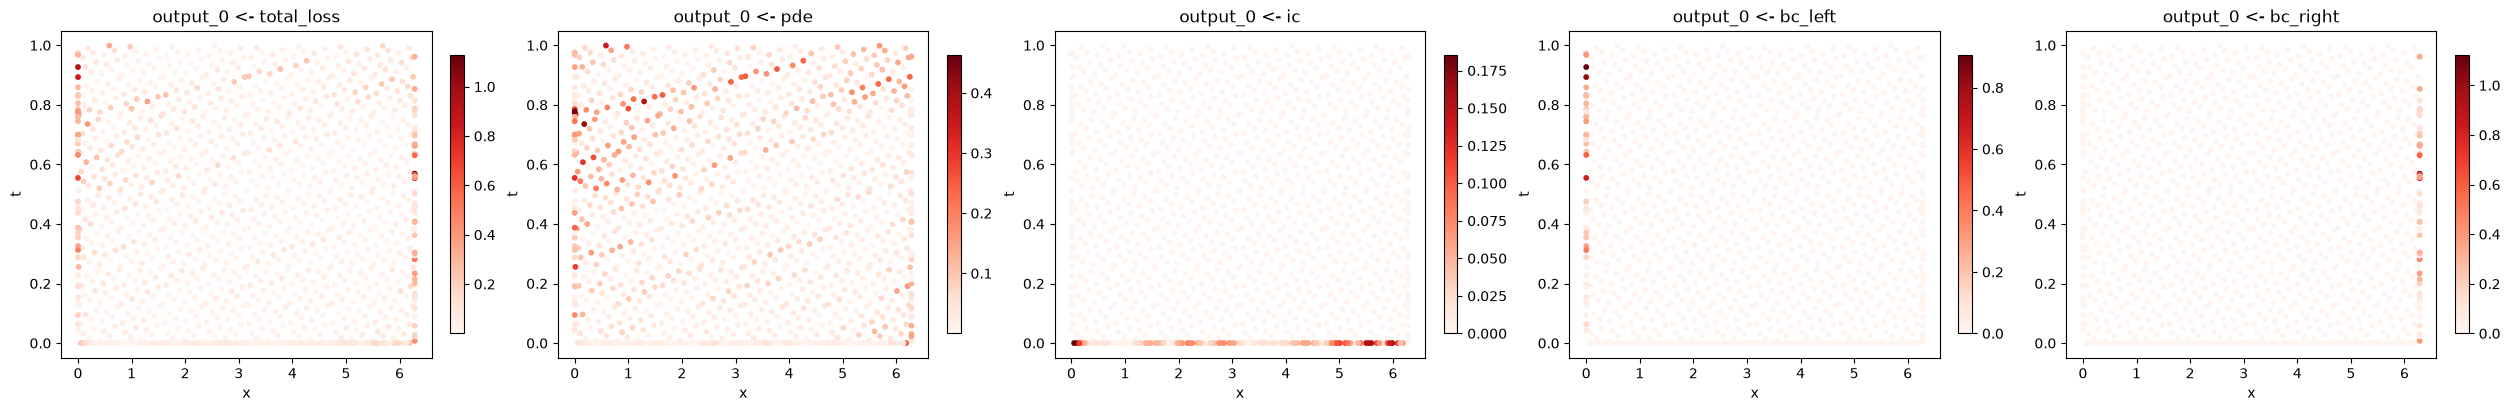

In [11]:
fig, axes = plt.subplots(
    1, len(scores), figsize=(5 * len(scores), 4), constrained_layout=True
)
for ax, (name, s) in zip(axes, scores.items()):
    agg = np.abs(s).sum(axis=0)
    sc = ax.scatter(x_train_np[:, 0], x_train_np[:, 1], c=agg, cmap="Reds", s=10)
    ax.set_title(f"output_0 <- {name}")
    ax.set_xlabel("x")
    ax.set_ylabel("t")
    fig.colorbar(sc, ax=ax, shrink=0.85)
plt.show()

## 10. Point-wise influence heatmaps

For four random test points (rows, marked with a black x), each training point is coloured by its signed influence on the prediction at that test point, one column per train term. Red pushes the prediction up, blue pushes it down. Note that the individual signs are quite noisy.

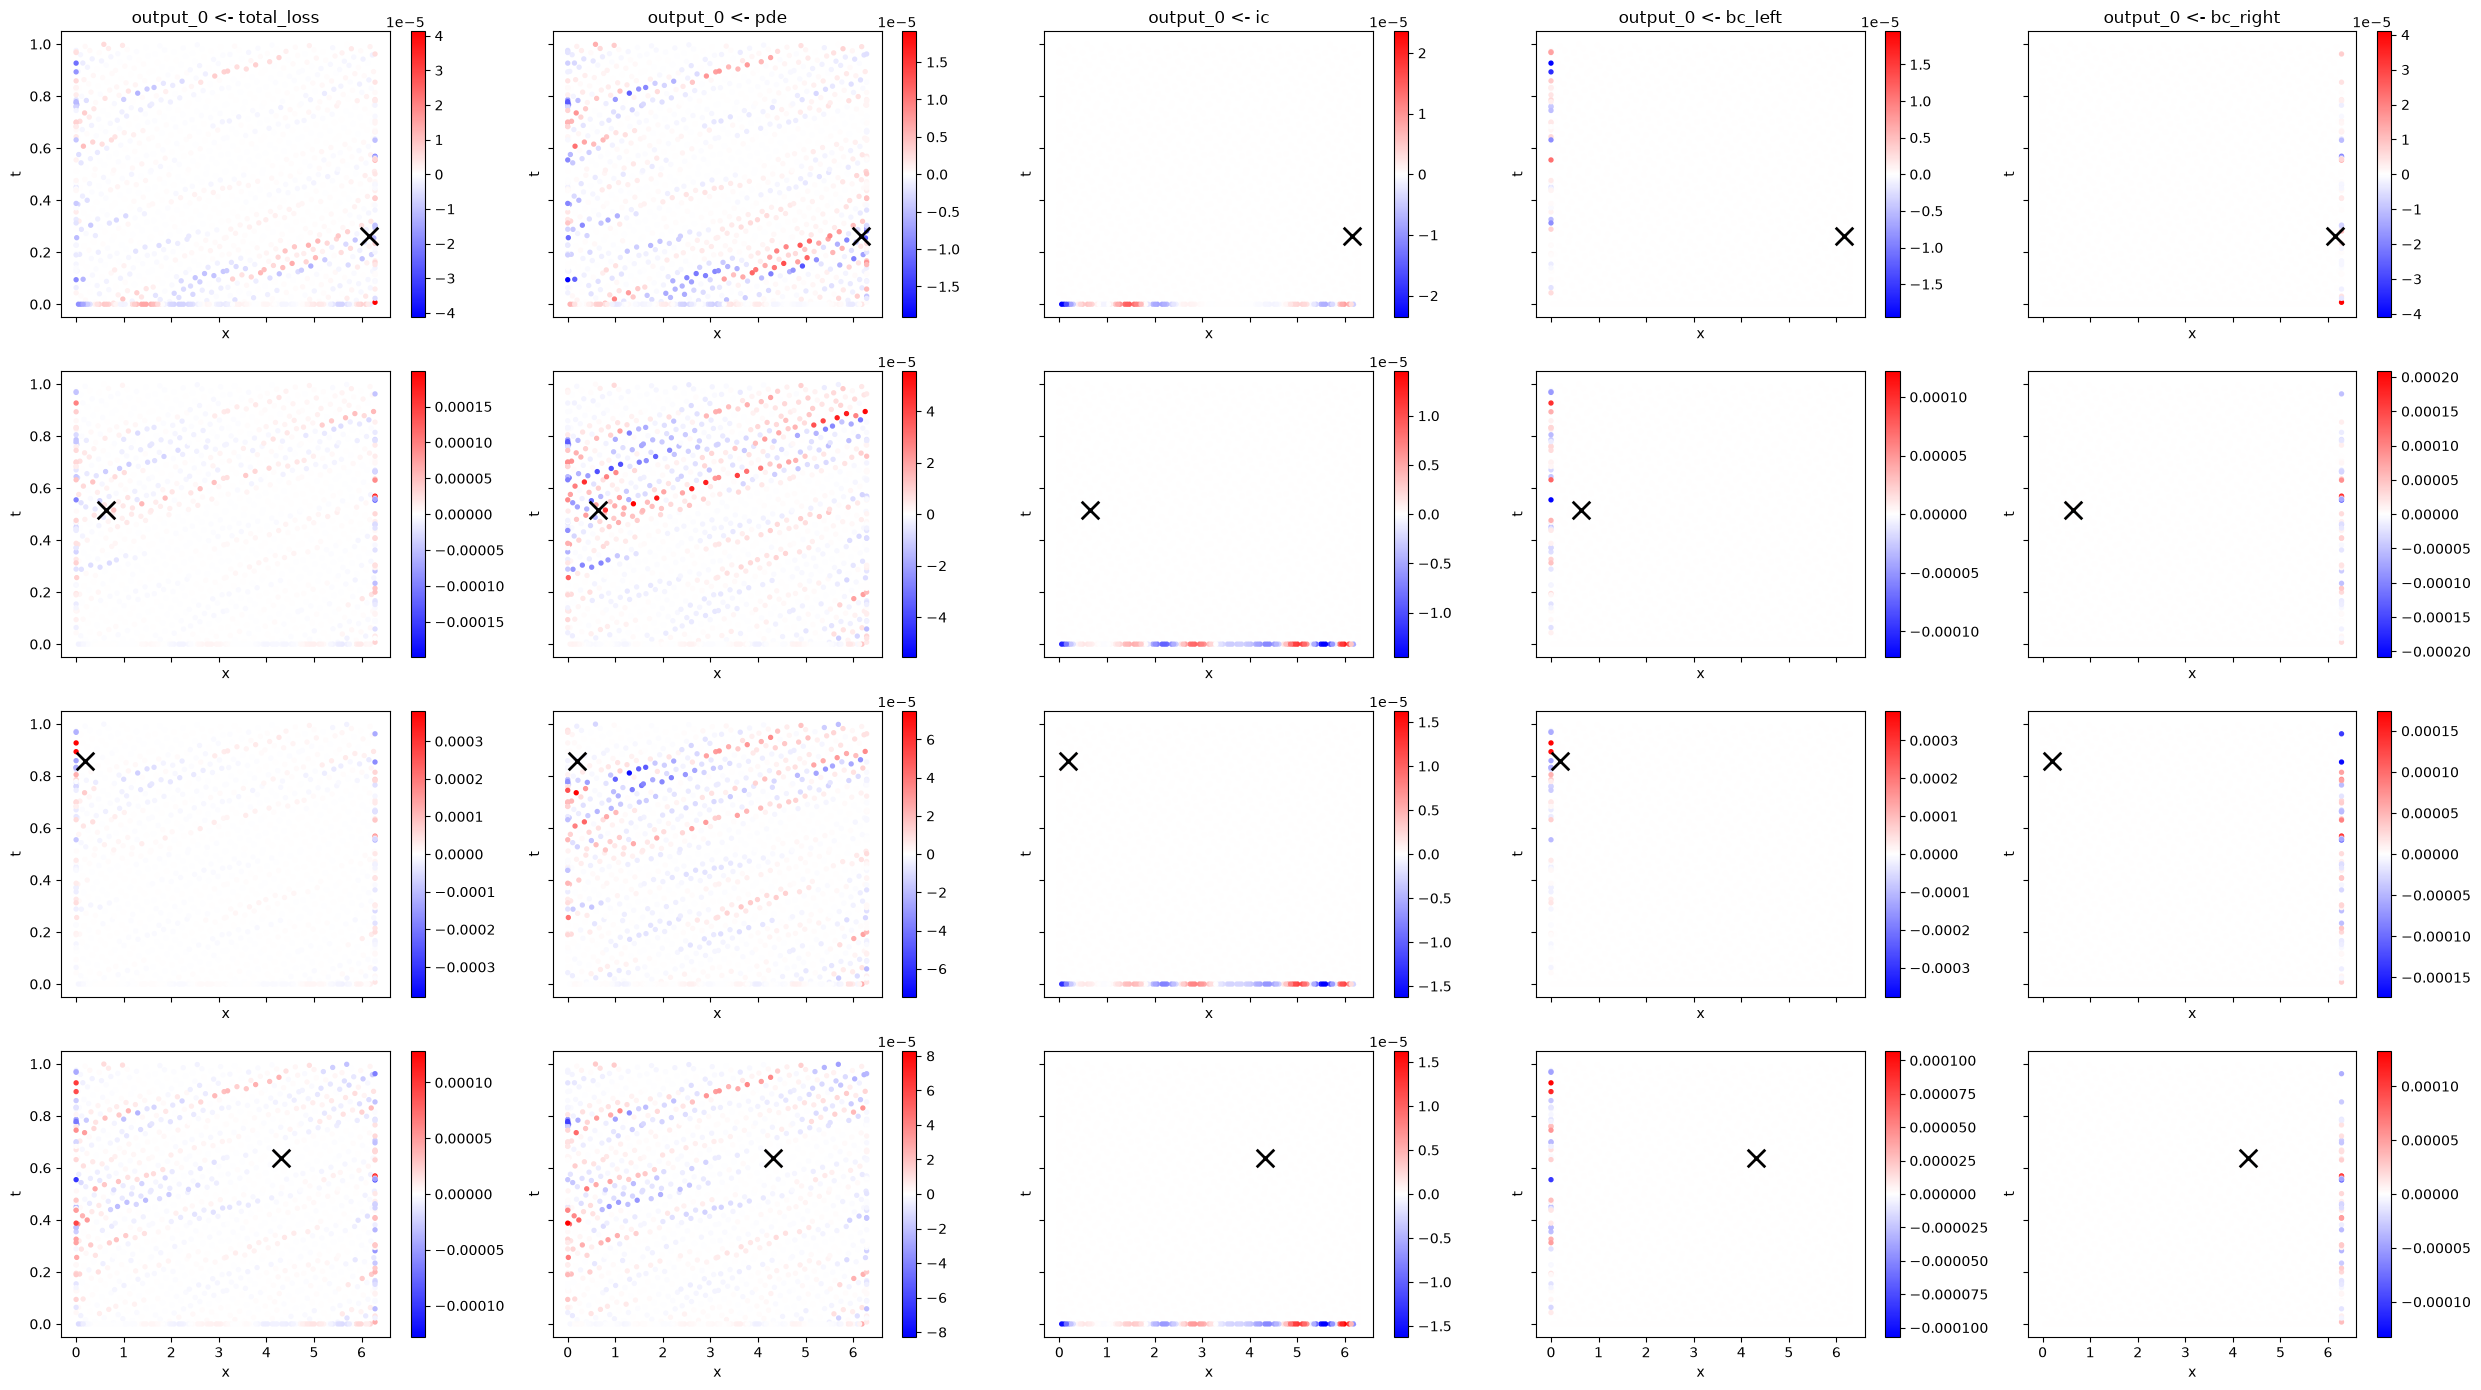

In [12]:
rng = np.random.default_rng(0)
test_indices = rng.choice(len(candidate_points), size=4, replace=False)

fig, axes = plt.subplots(
    len(test_indices),
    len(scores),
    figsize=(5 * len(scores), 3.5 * len(test_indices)),
    sharex=True,
    sharey=True,
)
for row, test_idx in enumerate(test_indices):
    for col, (name, s) in enumerate(scores.items()):
        plot_point_influence(
            train_x=x_train_np,
            candidate_x=candidate_points,
            scores=s,
            test_idx=int(test_idx),
            ax=axes[row, col],
            title=f"output_0 <- {name}" if row == 0 else None,
        )
fig.tight_layout()
plt.show()

### Pick the point yourself

Interactive version of the plot above. Choose the *test term* (what is explained, $f$) and the *train term* (through which loss term, $L$), then click on the plot:

- **test point**: the click is the test point $z$ (snapped to the nearest test-grid point, marked with a black x). The training points are coloured by their influence on $z$ (one row of the influence matrix).
- **train point**: the click selects the nearest training point $x$ (black x). The test grid is coloured by the influence of $x$ on every test point (one column of the influence matrix).

The matrices from section 8 are reused; any other `(test term, train term)` pair is computed on the first click and cached. 

In [13]:
%matplotlib widget
import ipywidgets as widgets

TEST_TERMS = {"output_0": "output_0", **train_terms}
matrices = {("output_0", name): s for name, s in scores.items()}  # (test term, train term) -> [n_test, n_train]
domain_span = np.array([x_end - x_start, t_end - t_start])
xx, tt = (candidate_points[:, k].reshape(100, 100) for k in (0, 1))
clicked = np.array([np.pi, 0.5])  # (x, t) of the last click


def influence_matrix(test_term: str, train_term: str) -> np.ndarray:
    if (test_term, train_term) not in matrices:
        matrices[test_term, train_term] = compute_influence_matrix(
            if_instance,
            residual_fn,
            test_term=TEST_TERMS[test_term],
            train_term=train_terms[train_term],
            candidate_points=candidate_points,
            batch_size=256,
        )
    return matrices[test_term, train_term]


def nearest(points: np.ndarray) -> int:
    """Index of the point closest to the click, distances scaled by the domain extent."""
    return int(np.argmin(np.sum(((points - clicked) / domain_span) ** 2, axis=1)))


test_term_select = widgets.Dropdown(options=list(TEST_TERMS), description="test term")
train_term_select = widgets.Dropdown(options=list(train_terms), description="train term")
click_on = widgets.ToggleButtons(options=["test point", "train point"], description="click on a")
status = widgets.Label()

with plt.ioff():
    fig = plt.figure(figsize=(7, 4.5))
fig.canvas.header_visible = False


def draw() -> None:
    status.value = f"computing {test_term_select.value} <- {train_term_select.value} ..."
    s = influence_matrix(test_term_select.value, train_term_select.value)
    title = f"{test_term_select.value} <- {train_term_select.value}"
    fig.clf()
    ax = fig.add_subplot()
    if click_on.value == "test point":
        i = nearest(candidate_points)
        plot_point_influence(
            x_train_np, candidate_points, s, i, ax=ax,
            title=f"{title}, z = ({candidate_points[i, 0]:.2f}, {candidate_points[i, 1]:.2f})",
        )
    else:
        j = nearest(x_train_np)
        column = s[:, j]
        lim = float(np.abs(column).max()) or 1.0
        pm = ax.pcolormesh(xx, tt, column.reshape(100, 100), cmap="bwr", vmin=-lim, vmax=lim)
        ax.scatter(x_train_np[:, 0], x_train_np[:, 1], c="gray", s=4)
        ax.scatter(*x_train_np[j], marker="x", c="black", s=160, linewidths=2)
        ax.set_xlabel("x")
        ax.set_ylabel("t")
        ax.set_title(f"{title}, x = ({x_train_np[j, 0]:.2f}, {x_train_np[j, 1]:.2f})")
        fig.colorbar(pm, ax=ax)
    fig.canvas.draw_idle()
    status.value = "click on the plot to pick another point"


def on_click(event) -> None:
    if event.inaxes is fig.axes[0]:  # ignore clicks on the colorbar
        clicked[:] = (event.xdata, event.ydata)
        draw()


fig.canvas.mpl_connect("button_press_event", on_click)
for w in (test_term_select, train_term_select, click_on):
    w.observe(lambda _: draw(), names="value")
draw()
display(widgets.VBox([widgets.HBox([test_term_select, train_term_select, click_on]), status, fig.canvas]))

## 11. Loss-term decomposition: fractions and cancellation

For the prediction `output_0`, we ask: of the total influence reaching a test point, how much flows through each training-side loss term (`pde`, `ic`, `bc_left`, `bc_right`)? 
The linearity of the influence function allows us to calculate this.
We calculate the relative absolute contribution of loss term $L_i$ for test point $x$ and training point $z$ as:
$$
r_{L_i}(x,z) = \frac{| \operatorname{Inf}_{\theta_0}^{L_i \to f}(x,z) |}{\sum_{j} | \operatorname{Inf}_{\theta_0}^{L_j \to f}| }
$$
i.e., the share of the total absolute influence that comes through this term. The fractions sum to 1 per test point.

Since the individual influences can have opposite signs, we also report the cancellation score
$$
\kappa = 1 - \frac{| \sum_j \operatorname{Inf}_{\theta_0}^{L_j \to f}(x,z) |}{\sum_{j} | \operatorname{Inf}_{\theta_0}^{L_j \to f}| }
= 1 - \frac{| \operatorname{Inf}_{\theta_0}^{L \to f}(x,z) |}{\sum_{j} | \operatorname{Inf}_{\theta_0}^{L_j \to f}| }
$$
where $L = \sum_j L_j$ is the total, non-decomposed loss. $\kappa = 0$ means all terms push in the same direction and $\kappa$ close to 1 means they largely cancel.

Per test point, the code sums numerator and denominator of $r_{L_i}$ over all training points $z$ and averages $\kappa$ over $z$. The plot bins the test points by $t$ and shows the mean per bin.

mean fraction per term:
  pde: 0.680
  ic: 0.079
  bc_left: 0.105
  bc_right: 0.136
mean coherence: 0.970  (cancellation = 0.030)


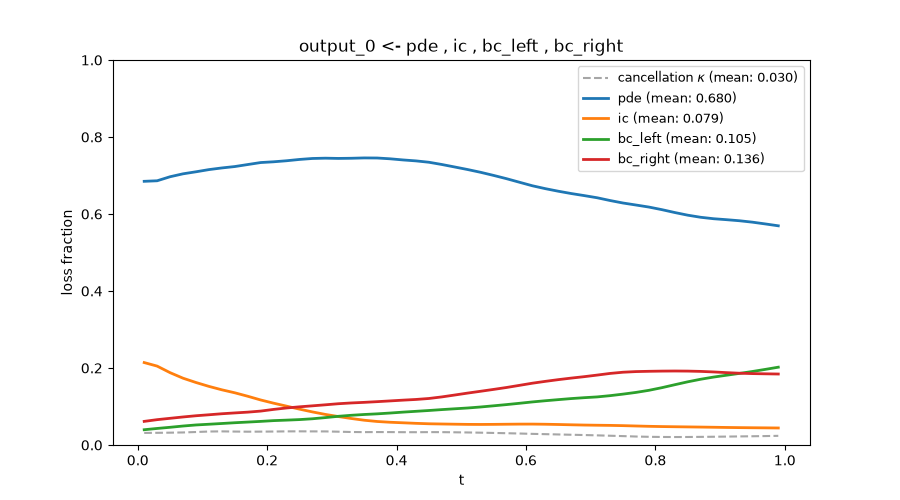

In [14]:
decomp = compute_loss_fractions(
    if_instance,
    residual_fn,
    candidate_points=candidate_points,
    test_term="output_0",
    train_terms=TERMS,
    batch_size=256,
)

print("mean fraction per term:")
for term, frac in decomp["fractions"].items():
    print(f"  {term}: {frac.mean():.3f}")
print(f"mean coherence: {decomp['coherence'].mean():.3f}  (cancellation = {1 - decomp['coherence'].mean():.3f})")

fig, ax = plt.subplots(figsize=(9, 5))
plot_loss_fractions_lineplot(decomp, dim=1, num_bins=50, ax=ax, dim_label="t")
plt.show()